# Customer Transaction Prediction

## MACHINE LEARNING CLASSIFICATION PROJECT

## Running this notebook locally

Place an authorized copy of the dataset at `data/train.csv` before running the notebook. Keep private or licensed data out of the public repository; the `data/` directory should remain local and be excluded by `.gitignore`.

Existing safe charts, aggregate outputs, and evaluation results are retained to avoid requiring a full rerun just to view the notebook. They reflect the original run and may differ when using another dataset or environment.


# Table of Contents

1. Problem Statement
2. Data Understanding
3. Exploratory Data Analysis (EDA)
4. Data Preprocessing
5. Model Building
6. Model Comparison
7. Effect of Feature Scaling
8. Model Improvement
   - Handling Class Imbalance (SMOTE)
   - Logistic Regression after SMOTE
   - XGBoost after SMOTE
   - Hyperparameter Tuning
   - Threshold Optimization
9. Why Logistic Regression?
10. Final Model Comparison
11. ROC Curve
12. Precision-Recall Curve
13. Feature Importance
14. Saving the Final Model
15. Final Conclusion
16. Business Impact
17. Business Recommendation
18. Limitations


## 1.Problem Statement

The objective of this project is to build a machine learning model that predicts whether a customer will make a specific transaction based on 200 anonymized numerical features. The target variable is binary, where **0** indicates that the customer will not make a transaction and **1** indicates that the customer will make a transaction.

Since the target variable has two possible outcomes, this is a **binary classification** problem. Multiple machine learning algorithms will be trained and evaluated to identify the model that provides the best predictive performance.

# 2.Data Understanding

## Import Libraries

In this section, the required Python libraries are imported for data manipulation, numerical computation, data visualization, machine learning model development, and model evaluation.

In [1]:
#data manipulation
import pandas as pd
import numpy as np

#data visualization
import matplotlib.pyplot as plt
import seaborn as sns

#ignore warnings
import warnings
warnings.filterwarnings("ignore")

## Load the Dataset

The dataset is loaded into the Python environment to begin the data analysis process. Once loaded, it can be explored, cleaned, visualized, and prepared for building machine learning models.


In [2]:
from pathlib import Path
DATA_PATH = Path("data/train.csv")
df = pd.read_csv(DATA_PATH)

In [ ]:
df.head()

In [ ]:
df.tail()

## Dataset Shape

The shape of the dataset is examined to determine the total number of observations (rows) and features (columns). Understanding the dataset dimensions provides an overview of its size before further analysis.

In [5]:
df.shape

(200000, 202)

### Observation

- The dataset contains **200,000 rows** and **202 columns**.
- Among the 202 columns, **one column is the target variable (`target`)** and the remaining **201 columns are input features**.
- The dataset is sufficiently large, making it suitable for training and evaluating machine learning classification models.

## Dataset Columns

The column names are examined to understand the structure of the dataset, identify the target variable, and verify the available input features. Although the feature names are anonymized in this dataset, inspecting the columns helps confirm that the dataset has been loaded correctly.

In [6]:
list(df.columns)

['ID_code',
 'target',
 'var_0',
 'var_1',
 'var_2',
 'var_3',
 'var_4',
 'var_5',
 'var_6',
 'var_7',
 'var_8',
 'var_9',
 'var_10',
 'var_11',
 'var_12',
 'var_13',
 'var_14',
 'var_15',
 'var_16',
 'var_17',
 'var_18',
 'var_19',
 'var_20',
 'var_21',
 'var_22',
 'var_23',
 'var_24',
 'var_25',
 'var_26',
 'var_27',
 'var_28',
 'var_29',
 'var_30',
 'var_31',
 'var_32',
 'var_33',
 'var_34',
 'var_35',
 'var_36',
 'var_37',
 'var_38',
 'var_39',
 'var_40',
 'var_41',
 'var_42',
 'var_43',
 'var_44',
 'var_45',
 'var_46',
 'var_47',
 'var_48',
 'var_49',
 'var_50',
 'var_51',
 'var_52',
 'var_53',
 'var_54',
 'var_55',
 'var_56',
 'var_57',
 'var_58',
 'var_59',
 'var_60',
 'var_61',
 'var_62',
 'var_63',
 'var_64',
 'var_65',
 'var_66',
 'var_67',
 'var_68',
 'var_69',
 'var_70',
 'var_71',
 'var_72',
 'var_73',
 'var_74',
 'var_75',
 'var_76',
 'var_77',
 'var_78',
 'var_79',
 'var_80',
 'var_81',
 'var_82',
 'var_83',
 'var_84',
 'var_85',
 'var_86',
 'var_87',
 'var_88',
 'var_89

### Observation

- The dataset contains one identifier column (`ID_code`), one target column (`target`), and 200 anonymized numerical feature columns (`var_0` to `var_199`).
- Since the feature names are anonymized, their real-world meaning is not available. The machine learning models will learn patterns directly from these numerical features.

## Dataset Information

The dataset information is examined to understand the structure of the data, including the number of non-null values, data types of each column, and memory usage. This helps identify missing values and ensures that the data is suitable for further preprocessing and analysis.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


### Observation

- The dataset contains **200,000 entries** with **202 columns**.
- The **ID_code** column is of **object** data type and serves as the unique identifier.
- The **target** column is of **int64** data type, representing the binary class labels.
- All **200 feature columns (`var_0` to `var_199`)** are of **float64** data type.
- Every column contains **200,000 non-null values**, indicating that there are **no missing values** in the dataset.

## Descriptive Statistics

Descriptive statistics provide a statistical summary of the numerical features in the dataset. This helps in understanding the distribution, central tendency, and variability of the data before proceeding with exploratory data analysis and model development.

In [8]:
df.describe()

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,...,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,0.100490,10.679914,-1.627622,10.715192,6.796529,11.078333,-5.065317,5.408949,16.545850,0.284162,...,3.234440,7.438408,1.927839,3.331774,17.993784,-0.142088,2.303335,8.908158,15.870720,-3.326537
std,0.300653,3.040051,4.050044,2.640894,2.043319,1.623150,7.863267,0.866607,3.418076,3.332634,...,4.559922,3.023272,1.478423,3.992030,3.135162,1.429372,5.454369,0.921625,3.010945,10.438015
min,0.000000,0.408400,-15.043400,2.117100,-0.040200,5.074800,-32.562600,2.347300,5.349700,-10.505500,...,-14.093300,-2.691700,-3.814500,-11.783400,8.694400,-5.261000,-14.209600,5.960600,6.299300,-38.852800
25%,0.000000,8.453850,-4.740025,8.722475,5.254075,9.883175,-11.200350,4.767700,13.943800,-2.317800,...,-0.058825,5.157400,0.889775,0.584600,15.629800,-1.170700,-1.946925,8.252800,13.829700,-11.208475
50%,0.000000,10.524750,-1.608050,10.580000,6.825000,11.108250,-4.833150,5.385100,16.456800,0.393700,...,3.203600,7.347750,1.901300,3.396350,17.957950,-0.172700,2.408900,8.888200,15.934050,-2.819550
75%,0.000000,12.758200,1.358625,12.516700,8.324100,12.261125,0.924800,6.003000,19.102900,2.937900,...,6.406200,9.512525,2.949500,6.205800,20.396525,0.829600,6.556725,9.593300,18.064725,4.836800
max,1.000000,20.315000,10.376800,19.353000,13.188300,16.671400,17.251600,8.447700,27.691800,10.151300,...,18.440900,16.716500,8.402400,18.281800,27.928800,4.272900,18.321500,12.000400,26.079100,28.500700


### Observation

- All numerical features contain **200,000 observations**, indicating that there are no missing values.
- The mean values vary across the features, showing that the variables are centered around different numerical values.
- The standard deviations differ among the features, indicating varying levels of data dispersion.
- The minimum and maximum values also vary considerably, suggesting that the features are measured on different numerical scales and include both negative and positive values.

## Missing Value Analysis

Missing values are checked to determine whether any observations are absent from the dataset. Identifying missing values is an important preprocessing step because they can affect the performance of machine learning models and may require appropriate handling techniques.

In [9]:
df.isnull().sum()

ID_code    0
target     0
var_0      0
var_1      0
var_2      0
          ..
var_195    0
var_196    0
var_197    0
var_198    0
var_199    0
Length: 202, dtype: int64

### Observation

- All 202 columns contain **zero missing values**.
- Since no missing values are present, **no imputation or missing-value treatment is required** before proceeding with further analysis.

## Duplicate Record Analysis

Duplicate records are checked to identify whether the dataset contains repeated observations. Since `ID_code` is a unique identifier for each customer, it is excluded from the duplicate check. This ensures that duplicate detection is based only on the feature values and target variable.

In [10]:
df.drop(columns='ID_code').duplicated().sum()

0

### Observation

- No duplicate records were found after excluding the `ID_code` column.
- Since the dataset does not contain duplicate observations, no duplicate removal is required before further analysis and model development.

# 3.Exploratory Data Analysis (EDA)

### Target Variable Analysis

In [4]:
df['target'].value_counts()

target
0    179902
1     20098
Name: count, dtype: int64

In [5]:
df["target"].value_counts(normalize=True)*100

target
0    89.951
1    10.049
Name: proportion, dtype: float64

### Target Variable Distribution

The distribution of the target variable is visualized to understand the proportion of each class. This helps identify whether the dataset is balanced or imbalanced, which is an important consideration when selecting evaluation metrics and building classification models.

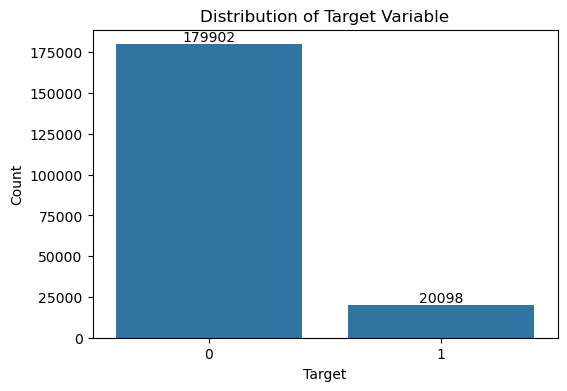

In [12]:
plt.figure(figsize=(6,4))

ax = sns.countplot(x='target', data=df)

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Target Variable")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()

### Observation

- The visualization clearly shows that the dataset is highly imbalanced.
- Class **0** (customers who did not make a transaction) represents the majority of the observations.
- Class **1** (customers who made a transaction) represents a much smaller proportion of the dataset.
- This imbalance should be considered during model evaluation by using appropriate performance metrics such as Precision, Recall, F1-score, and ROC-AUC, rather than relying solely on accuracy.

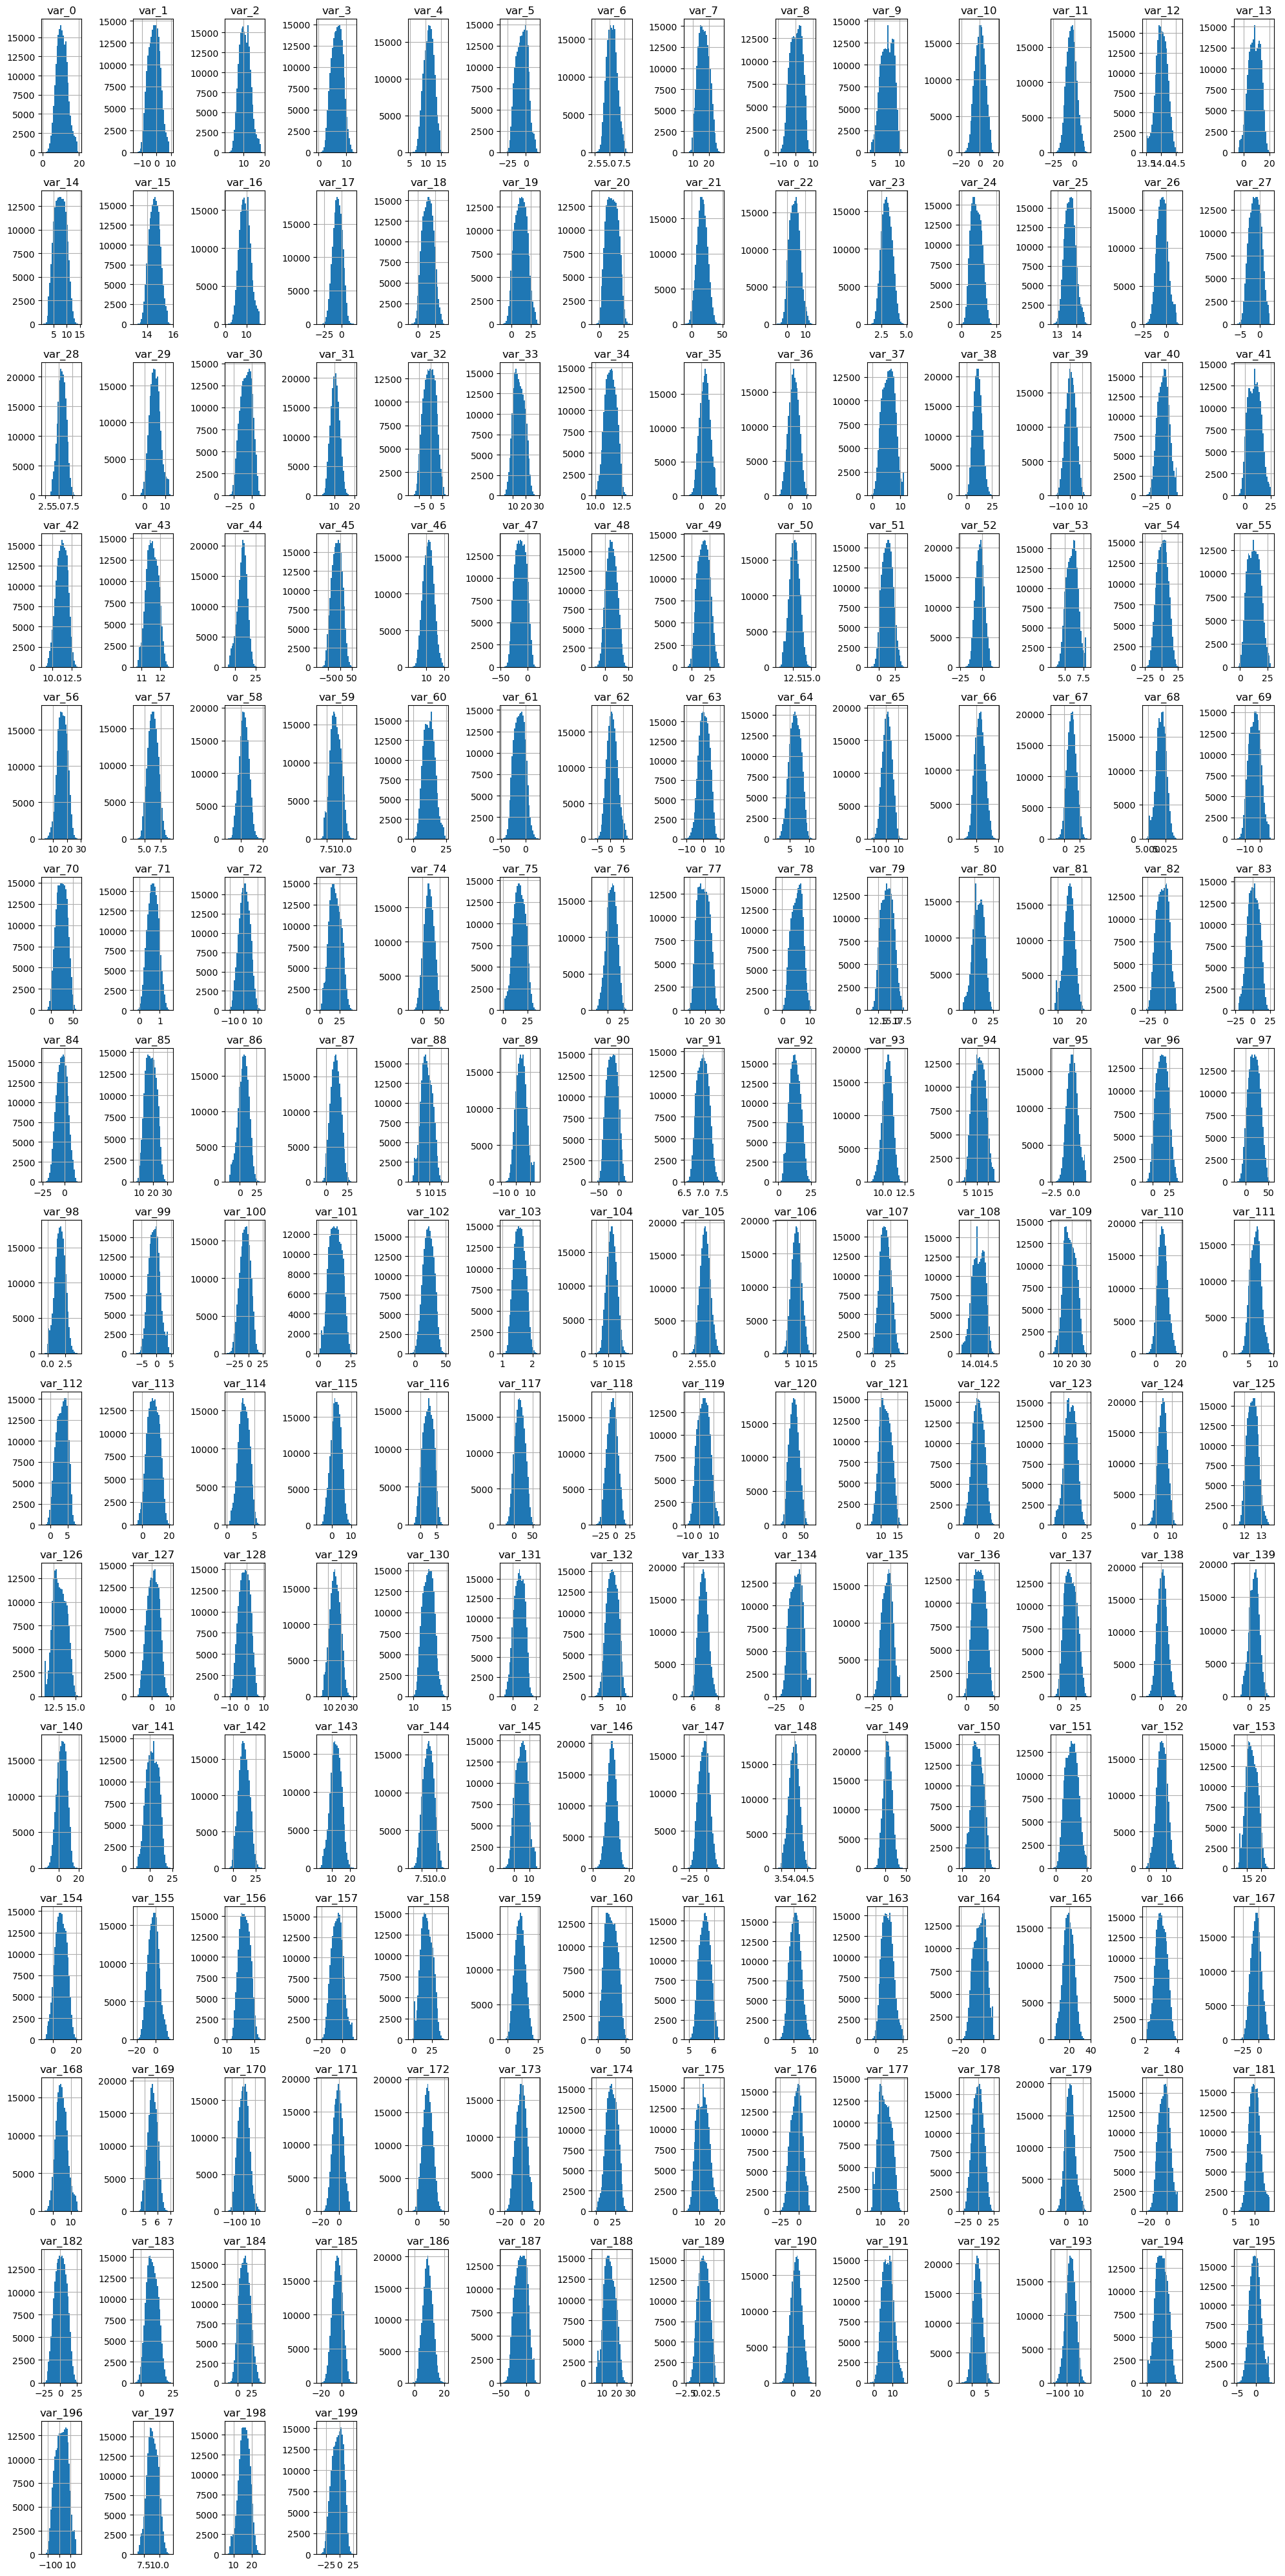

In [13]:
df.drop(columns=['ID_code', 'target']).hist(
    figsize=(20, 40),
    bins=30
)
plt.tight_layout()
plt.show()

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
target,200000.0,0.100490,0.300653,0.0000,0.000000,0.00000,0.000000,1.0000
var_0,200000.0,10.679914,3.040051,0.4084,8.453850,10.52475,12.758200,20.3150
var_1,200000.0,-1.627622,4.050044,-15.0434,-4.740025,-1.60805,1.358625,10.3768
var_2,200000.0,10.715192,2.640894,2.1171,8.722475,10.58000,12.516700,19.3530
var_3,200000.0,6.796529,2.043319,-0.0402,5.254075,6.82500,8.324100,13.1883
...,...,...,...,...,...,...,...,...
var_195,200000.0,-0.142088,1.429372,-5.2610,-1.170700,-0.17270,0.829600,4.2729
var_196,200000.0,2.303335,5.454369,-14.2096,-1.946925,2.40890,6.556725,18.3215
var_197,200000.0,8.908158,0.921625,5.9606,8.252800,8.88820,9.593300,12.0004
var_198,200000.0,15.870720,3.010945,6.2993,13.829700,15.93405,18.064725,26.0791


### Observation
##### Distribution of All Numerical Features

The histogram below shows the distribution of all 200 numerical features in the dataset. Most features appear to follow approximately normal distributions with varying means and standard deviations. Since visualizing all features simultaneously makes detailed inspection difficult, a subset of features is analyzed separately below.

In [ ]:
first5 = df.drop(columns=["ID_code", "target"]).iloc[:, :5]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(first5.columns):

    # Histogram
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        stat="density",
        color="skyblue",
        edgecolor="black",
        alpha=0.6,
        ax=axes[i]
    )

    # KDE line
    sns.kdeplot(
        data=df,
        x=col,
        color="red",      # <-- Separate color
        linewidth=2.5,
        ax=axes[i]
    )

    axes[i].set_title(col)

# Remove empty subplot
fig.delaxes(axes[-1])

plt.suptitle("First Five Features: Histogram with KDE", fontsize=16)
plt.tight_layout()
plt.show()

### Observation

- The histograms and KDE curves of the first five numerical features indicate that most variables exhibit approximately bell-shaped distributions.
- Features such as **var_0**, **var_1**, **var_3**, and **var_4** appear close to a normal distribution with only slight skewness.
- **var_2** shows a small secondary peak, suggesting a mild multimodal pattern or the presence of multiple underlying groups.
- The distributions have different means and variances, indicating that the numerical features are measured on different scales.
- Overall, the selected features do not exhibit severe skewness or extreme distributional irregularities.

In [ ]:
last5 = df.drop(columns=["ID_code", "target"]).iloc[:, -5:]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(last5.columns):

    sns.histplot(
        data=df,
        x=col,
        bins=30,
        stat="density",
        color="lightgreen",
        edgecolor="black",
        alpha=0.6,
        ax=axes[i]
    )

    sns.kdeplot(
        data=df,
        x=col,
        color="darkblue",
        linewidth=2.5,
        ax=axes[i]
    )

    axes[i].set_title(col)

fig.delaxes(axes[-1])

plt.suptitle("Last Five Features: Histogram with KDE", fontsize=16)
plt.tight_layout()
plt.show()

### Observation

- The last five numerical features also display approximately continuous and near-normal distributions.
- Most variables are unimodal with smooth KDE curves, indicating no significant distributional abnormalities.
- Features such as **var_195**, **var_196**, **var_198**, and **var_199** exhibit slight skewness and varying spreads, while **var_197** appears more symmetric.
- The consistency between the first and last set of features suggests that the anonymized variables follow similar statistical characteristics throughout the dataset.
- These observations indicate that the dataset consists primarily of continuous numerical variables with relatively stable distribution patterns.

## Transition to Correlation Analysis

The feature distribution plots do not indicate any obvious extreme distributions that require immediate outlier treatment. Since the primary objective is to understand the relationships among the features before model building, the analysis proceeds with correlation analysis. If outliers are found to affect model performance during evaluation, they can be investigated and handled in the preprocessing stage.

## Correlation Analysis

Correlation analysis is performed to examine the relationships among the numerical features. It helps identify highly correlated variables, detect redundancy, and understand whether multiple features carry similar information. This understanding is useful before model development, particularly for algorithms that are sensitive to multicollinearity.

In [15]:
corr_matrix = df.drop(columns="ID_code").corr()

In [16]:
corr_matrix

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
target,1.000000,0.052390,0.050343,0.055870,0.011055,0.010915,0.030979,0.066731,-0.003025,0.019584,...,0.055973,0.047114,-0.042858,-0.017709,-0.022838,0.028285,0.023608,-0.035303,-0.053000,0.025434
var_0,0.052390,1.000000,-0.000544,0.006573,0.003801,0.001326,0.003046,0.006983,0.002429,0.004962,...,0.002752,0.000206,-0.005373,0.001616,-0.001514,0.002073,0.004386,-0.000753,-0.005776,0.003850
var_1,0.050343,-0.000544,1.000000,0.003980,0.000010,0.000303,-0.000902,0.003258,0.001511,0.004098,...,0.006627,0.003621,-0.002604,0.001153,-0.002557,-0.000785,-0.000377,-0.004157,-0.004861,0.002287
var_2,0.055870,0.006573,0.003980,1.000000,0.001001,0.000723,0.001569,0.000883,-0.000991,0.002648,...,0.000197,0.001285,-0.003400,0.000549,0.002104,-0.001070,0.003952,0.001078,-0.000877,0.003855
var_3,0.011055,0.003801,0.000010,0.001001,1.000000,-0.000322,0.003253,-0.000774,0.002500,0.003553,...,0.000151,0.002445,-0.001530,-0.001699,-0.001054,0.001206,-0.002800,0.001164,-0.001651,0.000506
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
var_195,0.028285,0.002073,-0.000785,-0.001070,0.001206,0.003706,-0.001274,0.001244,0.001854,0.001396,...,0.004571,0.000870,-0.004745,-0.003143,-0.001201,1.000000,0.002517,-0.004170,-0.000536,0.002042
var_196,0.023608,0.004386,-0.000377,0.003952,-0.002800,0.000513,0.002880,0.005378,0.001045,-0.003242,...,-0.000847,0.002466,-0.001386,-0.005308,-0.005040,0.002517,1.000000,-0.000454,0.000253,0.000607
var_197,-0.035303,-0.000753,-0.004157,0.001078,0.001164,-0.000046,-0.000535,-0.003565,0.003466,-0.004583,...,-0.004974,0.000906,-0.000527,0.005068,0.000884,-0.004170,-0.000454,1.000000,0.001183,0.004991
var_198,-0.053000,-0.005776,-0.004861,-0.000877,-0.001651,-0.001821,-0.000953,-0.003025,0.000650,0.002950,...,-0.000153,-0.000067,0.003451,0.001646,0.003194,-0.000536,0.000253,0.001183,1.000000,-0.004731


### Observation

- The correlation matrix indicates that most feature pairs have very low correlation coefficients.
- No obvious strong linear relationships are observed among the numerical features from the initial inspection.
- The target variable also exhibits relatively weak linear correlations with individual features.
- This suggests that the dataset has low multicollinearity and that machine learning models capable of learning non-linear relationships may be beneficial.

### Highly Correlated Feature Pairs


In [ ]:
# Absolute correlation matrix
corr_matrix = df.drop(columns="ID_code").corr().abs()

# Keep only the upper triangle (excluding the diagonal)
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Display the top 20 highest correlations
top_corr = upper.stack().sort_values(ascending=False)

top_corr.head(20)

### Observation

- The highest correlation between an individual feature and the target variable is approximately **0.08**, indicating a weak linear relationship.
- Most features exhibit only low correlation with the target variable.
- No single feature appears to be a strong predictor on its own.
- The prediction is likely to depend on the combined effect of multiple features rather than any single feature.
- Machine learning models capable of capturing complex and non-linear relationships are expected to perform better on this dataset.

### EDA Summary

Based on the exploratory data analysis, the dataset contains no missing values, no duplicate records, and no obvious issues requiring immediate preprocessing. The feature distributions appear reasonably well-behaved, and correlation analysis indicates low linear relationships among the features and with the target variable. Therefore, the exploratory analysis is considered complete, and the workflow now proceeds to the data preprocessing stage for model development.

# 4.Data Preprocessing

## Feature and Target Separation

Before training a machine learning model, the dataset is divided into input features (`X`) and the target variable (`y`). The feature variables contain the information used by the model to learn patterns, while the target variable represents the outcome that the model is trained to predict.

In [18]:
X = df.drop(columns=['ID_code','target'])

In [ ]:
X.head()

In [20]:
y = df['target']

In [ ]:
y.head()

### Observation

- The feature matrix (`X`) contains **201 input features**, including the anonymized variables and excluding the identifier and target columns.
- The target vector (`y`) contains the binary class labels that the machine learning models will learn to predict.

## Train-Test Split

The dataset is divided into training and testing sets to evaluate the machine learning models on unseen data. The training set is used to learn patterns from the data, while the testing set is used to assess the model's ability to generalize. Since the target variable is imbalanced, stratified sampling is used to preserve the class distribution in both the training and testing sets.

In [22]:
from sklearn.model_selection import train_test_split

In [23]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y 
)

In [24]:
print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)
print("Training Target   :", y_train.shape)
print("Testing Target    :", y_test.shape)

Training Features : (160000, 200)
Testing Features  : (40000, 200)
Training Target   : (160000,)
Testing Target    : (40000,)


### Observation

- The dataset has been split into **80% training data** and **20% testing data**.
- The training set will be used to train the machine learning models, while the testing set will be used to evaluate their performance.
- Stratified sampling has preserved the original class distribution in both subsets, ensuring a fair evaluation of the models.

## Feature Scaling

Feature scaling is performed to standardize the numerical features so that they are measured on a comparable scale. This is particularly important for machine learning algorithms such as Logistic Regression and Support Vector Machine (SVM), which are sensitive to the magnitude of feature values. Since the feature distributions are approximately normal, **StandardScaler** is used to transform the data to have a mean of 0 and a standard deviation of 1.

In [25]:
from sklearn.preprocessing import StandardScaler

In [26]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5.Model Building

## Logistic Regression

Logistic Regression is selected as the baseline classification model because it is simple, computationally efficient, and easy to interpret. Its performance provides a benchmark against which more complex machine learning models can be compared.

In [27]:
from sklearn.linear_model import LogisticRegression

In [28]:
lr = LogisticRegression(random_state=42)

In [29]:
lr.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

### Model Prediction

After training, the Logistic Regression model is used to predict the class labels for the testing dataset. These predictions are then evaluated using appropriate classification metrics.

In [30]:
# Predict on the test set
y_pred_lr = lr.predict(X_test_scaled)

In [ ]:
X_test_scaled

## Model Evaluation

### Confusion Matrix

A confusion matrix summarizes the classification performance of the model by comparing the actual class labels with the predicted class labels. It provides a detailed breakdown of correct and incorrect predictions and serves as the foundation for calculating evaluation metrics such as Accuracy, Precision, Recall, and F1-score.

In [32]:
from sklearn.metrics import confusion_matrix

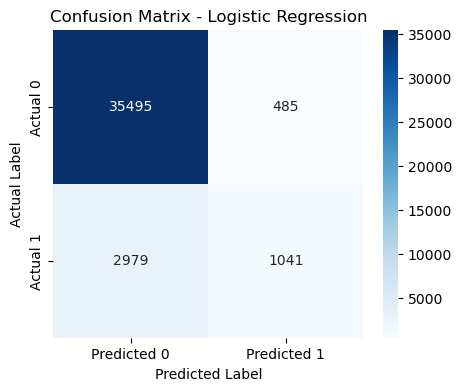

In [33]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_lr)

# Visualize confusion matrix
plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted 0', 'Predicted 1'],
    yticklabels=['Actual 0', 'Actual 1']
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### Observation

- The model correctly classified **35,495** non-transaction customers (True Negatives).
- It correctly identified **1,041** customers who made a transaction (True Positives).
- The model produced **485 False Positives**, where non-transaction customers were incorrectly predicted as transaction customers.
- It produced **2,979 False Negatives**, indicating that many customers who actually made a transaction were missed.
- Since the number of False Negatives is considerably higher than the number of True Positives, additional evaluation metrics such as Recall, F1-score, and ROC-AUC are required to better assess the model's performance on the minority class.

### Classification Metrics

To comprehensively evaluate the Logistic Regression model, multiple performance metrics are calculated. Since the dataset is imbalanced, relying solely on accuracy may be misleading. Therefore, Precision, Recall, F1-score, and ROC-AUC are also evaluated to assess the model's ability to correctly identify the minority class.

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

In [35]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_lr)
precision = precision_score(y_test, y_pred_lr)
recall = recall_score(y_test, y_pred_lr)
f1 = f1_score(y_test, y_pred_lr)

# Probability predictions for ROC-AUC
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob_lr)

# Print results
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.9134
Precision: 0.6822
Recall   : 0.2590
F1 Score : 0.3754
ROC-AUC  : 0.8599


In [36]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.92      0.99      0.95     35980
           1       0.68      0.26      0.38      4020

    accuracy                           0.91     40000
   macro avg       0.80      0.62      0.66     40000
weighted avg       0.90      0.91      0.90     40000



In [37]:
baseline_accuracy = accuracy
baseline_precision = precision
baseline_recall = recall
baseline_f1 = f1
baseline_roc_auc = roc_auc

### Observation

- The Logistic Regression model achieved an overall **accuracy of 91%**.
- The model performed very well in identifying the majority class (Class 0), achieving an F1-score of **0.95**.
- For the minority class (Class 1), the model achieved a **precision of 68%**, indicating that most predicted transaction customers were correctly classified.
- However, the **recall was only 26%**, meaning the model failed to identify a large proportion of customers who actually made a transaction.
- Consequently, the **F1-score for the minority class was 0.38**, suggesting that although the model is a useful baseline, it is not sufficiently effective at detecting the minority class.
- Since this is an imbalanced classification problem, subsequent models such as Decision Tree, Random Forest, and XGBoost will be evaluated to determine whether they improve the detection of the minority class.

## Decision Tree Classifier

Decision Tree is a non-linear supervised machine learning algorithm used for classification and regression tasks. It predicts the target variable by recursively splitting the dataset into smaller subsets based on feature values. Unlike Logistic Regression, Decision Trees can capture complex and non-linear relationships without requiring feature scaling.

In [38]:
from sklearn.tree import DecisionTreeClassifier

In [39]:
dt = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

In [40]:
dt.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=10, random_state=42)

### Model Prediction

In [41]:
y_pred_dt=dt.predict(X_test)

## Model Evaluation

### Confusion Matrix

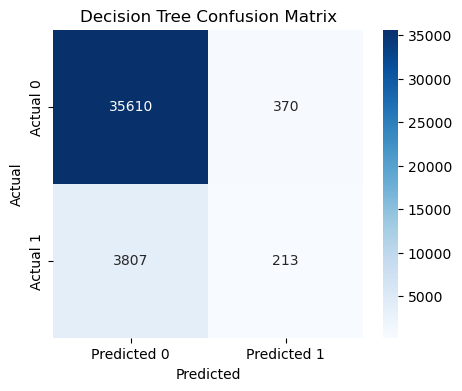

In [42]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted 0','Predicted 1'],
    yticklabels=['Actual 0','Actual 1']
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Observation

- The Decision Tree correctly classified the majority class (Class 0) with very few False Positives.
- However, it identified only **213** true positive cases while missing **3,807** actual transaction customers.
- Compared with Logistic Regression, the Decision Tree produced more False Negatives, indicating a lower ability to detect the minority class.
- Based on the confusion matrix, the Decision Tree is expected to have a lower Recall and F1-score for the minority class.

In [43]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

y_prob_dt = dt.predict_proba(X_test)[:,1]
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

print(f"Accuracy : {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"F1 Score : {f1_dt:.4f}")
print(f"ROC-AUC  : {roc_auc_dt:.4f}")

Accuracy : 0.8956
Precision: 0.3654
Recall   : 0.0530
F1 Score : 0.0925
ROC-AUC  : 0.6523


In [44]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.90      0.99      0.94     35980
           1       0.37      0.05      0.09      4020

    accuracy                           0.90     40000
   macro avg       0.63      0.52      0.52     40000
weighted avg       0.85      0.90      0.86     40000



### Observation

- The Decision Tree achieved an overall **accuracy of 90%**, which is comparable to Logistic Regression.
- However, its performance on the minority class was significantly weaker.
- The model achieved a **precision of 37%**, **recall of only 5%**, and an **F1-score of 0.09** for Class 1.
- The very low recall indicates that the Decision Tree failed to identify most customers who actually made a transaction.
- Compared with Logistic Regression, the baseline Decision Tree performed considerably worse in detecting the minority class. Therefore, it is not selected as the preferred baseline model at this stage.

## Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines the predictions of multiple Decision Trees to improve classification performance. By aggregating the results of many trees, Random Forest reduces overfitting, improves generalization, and produces more stable predictions than a single Decision Tree.

In [45]:
from sklearn.ensemble import RandomForestClassifier

In [46]:

rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    n_jobs=-1,
    random_state=42
)


In [47]:
rf.fit(X_train,y_train)

RandomForestClassifier(max_depth=10, n_estimators=50, n_jobs=-1,
                       random_state=42)

### Model Prediction

In [48]:
y_pred_rf = rf.predict(X_test)

## Model Evaluation

### Confusion Matrix

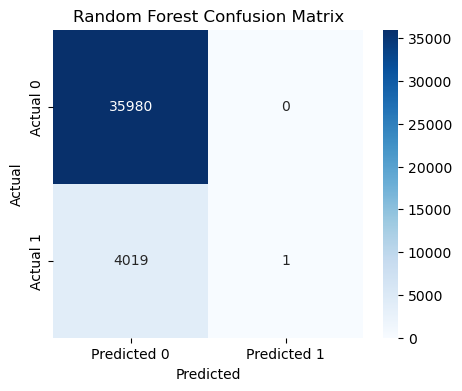

In [49]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted 0','Predicted 1'],
    yticklabels=['Actual 0','Actual 1']
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Observation

- The Random Forest model correctly classified **35,980** non-transaction customers (True Negatives).
- It identified only **1** customer who actually made a transaction (True Positive).
- The model produced **0 False Positives**, indicating that it almost never misclassified non-transaction customers as transaction customers.
- However, it produced **4,019 False Negatives**, meaning it failed to identify nearly all customers who actually made a transaction.
- Based on the confusion matrix, the model is highly biased towards the majority class (Class 0) and shows very poor performance in detecting the minority class (Class 1). Therefore, additional evaluation metrics such as Recall, F1-score, and ROC-AUC are essential to assess its performance.

In [50]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

y_prob_rf = rf.predict_proba(X_test)[:,1]
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1 Score : {f1_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")

print(classification_report(y_test, y_pred_rf))

Accuracy : 0.8995
Precision: 1.0000
Recall   : 0.0002
F1 Score : 0.0005
ROC-AUC  : 0.7884
              precision    recall  f1-score   support

           0       0.90      1.00      0.95     35980
           1       1.00      0.00      0.00      4020

    accuracy                           0.90     40000
   macro avg       0.95      0.50      0.47     40000
weighted avg       0.91      0.90      0.85     40000



### Observation

- The Random Forest model achieved an overall **accuracy of 89.95%**, which appears high due to the dominance of the majority class (Class 0).
- The model achieved a **precision of 100%** for the minority class because the only customer predicted as a transaction customer was correctly classified.
- However, the **recall was only 0.02%**, indicating that the model identified only **1 out of 4,020** actual transaction customers.
- Consequently, the **F1-score was nearly zero (0.0005)**, showing an extremely poor balance between precision and recall.
- The **ROC-AUC score of 0.7884** indicates that the model has some ability to distinguish between the two classes, but the default classification threshold resulted in almost all observations being classified as the majority class.
- Overall, the baseline Random Forest model performed poorly in detecting the minority class and is not suitable for this dataset in its current configuration. Further improvements such as hyperparameter tuning, class balancing techniques, or threshold optimization would be required.

## XGBoost Classifier

XGBoost (Extreme Gradient Boosting) is an ensemble learning algorithm based on the boosting technique. Unlike Random Forest, which builds trees independently, XGBoost builds trees sequentially, where each new tree attempts to correct the errors made by the previous trees. This approach often results in higher predictive performance, especially for structured tabular datasets.

In [ ]:
pip install xgboost

In [52]:
from xgboost import XGBClassifier

In [53]:
xgb = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

In [54]:
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

### Model Prediction

In [55]:
y_pred_xgb = xgb.predict(X_test)

## Model Evaluation

### Confusion Matrix

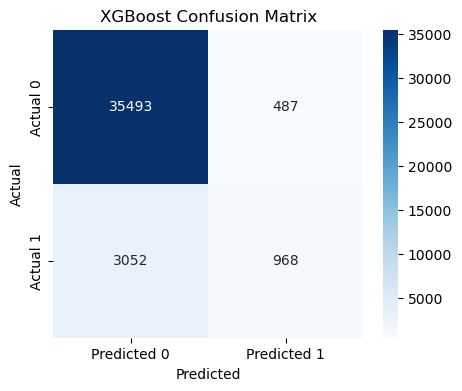

In [56]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted 0','Predicted 1'],
    yticklabels=['Actual 0','Actual 1']
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Observation

- The XGBoost model correctly classified **35,493** non-transaction customers (True Negatives).
- It correctly identified **968** customers who made a transaction (True Positives).
- The model produced **487 False Positives**, indicating that only a small number of non-transaction customers were incorrectly classified as transaction customers.
- However, it produced **3,052 False Negatives**, meaning that a considerable number of actual transaction customers were missed.
- Based on the confusion matrix, the baseline XGBoost model shows performance comparable to Logistic Regression in identifying both majority and minority classes. A detailed comparison using Precision, Recall, F1-score, and ROC-AUC is required to determine whether it provides an overall improvement.

In [57]:
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)

y_prob_xgb = xgb.predict_proba(X_test)[:,1]
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print(f"Accuracy : {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall   : {recall_xgb:.4f}")
print(f"F1 Score : {f1_xgb:.4f}")
print(f"ROC-AUC  : {roc_auc_xgb:.4f}")

print(classification_report(y_test, y_pred_xgb))

Accuracy : 0.9115
Precision: 0.6653
Recall   : 0.2408
F1 Score : 0.3536
ROC-AUC  : 0.8597
              precision    recall  f1-score   support

           0       0.92      0.99      0.95     35980
           1       0.67      0.24      0.35      4020

    accuracy                           0.91     40000
   macro avg       0.79      0.61      0.65     40000
weighted avg       0.90      0.91      0.89     40000



### Observation

- The XGBoost model achieved an overall **accuracy of 91.15%**, which is comparable to Logistic Regression.
- The model achieved a **precision of 66.53%**, indicating that most predicted transaction customers were correctly classified.
- The **recall was 24.08%**, showing that the model identified approximately one-fourth of the customers who actually made a transaction.
- The **F1-score of 0.3536** indicates a moderate balance between precision and recall, although it is slightly lower than that of Logistic Regression.
- The model achieved a **ROC-AUC score of 0.8597**, demonstrating a good ability to distinguish between transaction and non-transaction customers across different classification thresholds.
- Overall, the baseline XGBoost model produced performance comparable to Logistic Regression and has strong potential for improvement through hyperparameter tuning.

## Support Vector Machine (SVM)

Support Vector Machine (SVM) is a supervised machine learning algorithm used for classification tasks. It identifies the optimal decision boundary (hyperplane) that maximizes the margin between different classes. Since SVM is sensitive to the scale of input features, the standardized dataset is used for training and evaluation.

In [58]:
from sklearn.svm import LinearSVC

In [59]:
svm = LinearSVC(
    random_state=42,
    max_iter=5000
)

In [60]:
svm.fit(X_train_scaled, y_train)

LinearSVC(max_iter=5000, random_state=42)

### Model Prediction

In [61]:
y_pred_svm = svm.predict(X_test_scaled)

## Model Evaluation

### Confusion Matrix

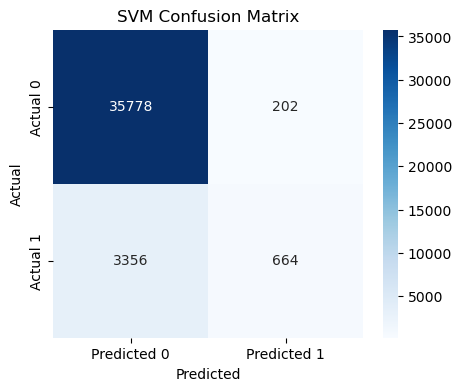

In [62]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted 0', 'Predicted 1'],
    yticklabels=['Actual 0', 'Actual 1']
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Observation

- The SVM model correctly classified **35,778** non-transaction customers (True Negatives).
- It correctly identified **664** customers who made a transaction (True Positives).
- The model produced **202 False Positives**, the lowest among all baseline models, indicating that it rarely misclassified non-transaction customers as transaction customers.
- However, it produced **3,356 False Negatives**, showing that many actual transaction customers were still missed.
- Based on the confusion matrix, the SVM model demonstrated a conservative prediction strategy by minimizing False Positives, but this resulted in a lower number of correctly identified transaction customers. Additional evaluation metrics are required to determine its overall effectiveness.

In [63]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)

print(f"Accuracy : {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall   : {recall_svm:.4f}")
print(f"F1 Score : {f1_svm:.4f}")

print(classification_report(y_test, y_pred_svm))

Accuracy : 0.9111
Precision: 0.7667
Recall   : 0.1652
F1 Score : 0.2718
              precision    recall  f1-score   support

           0       0.91      0.99      0.95     35980
           1       0.77      0.17      0.27      4020

    accuracy                           0.91     40000
   macro avg       0.84      0.58      0.61     40000
weighted avg       0.90      0.91      0.88     40000



### Observation

- The SVM model achieved an overall **accuracy of 91.11%**, which is comparable to Logistic Regression and XGBoost.
- The model achieved the **highest precision (76.67%)** among all baseline models, indicating that most customers predicted as transaction customers were correctly classified.
- However, the **recall was only 16.52%**, meaning that the model identified only a small proportion of customers who actually made a transaction.
- The **F1-score of 27.18%** reflects the trade-off between high precision and relatively low recall.
- Overall, the baseline SVM model was conservative in predicting the minority class. While it minimized false positive predictions, it failed to identify many actual transaction customers.

# 6.Model Comparison

The performance of all baseline machine learning models is compared using multiple evaluation metrics. Since the dataset is imbalanced, the comparison focuses not only on Accuracy but also on Precision, Recall, F1-score, and ROC-AUC to identify the most suitable model for predicting customer transactions.

In [64]:
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "SVM"
    ],
    "Accuracy": [
        accuracy,
        accuracy_dt,
        accuracy_rf,
        accuracy_xgb,
        accuracy_svm
    ],
    "Precision": [
        precision,
        precision_dt,
        precision_rf,
        precision_xgb,
        precision_svm
    ],
    "Recall": [
        recall,
        recall_dt,
        recall_rf,
        recall_xgb,
        recall_svm
    ],
    "F1-Score": [
        f1,
        f1_dt,
        f1_rf,
        f1_xgb,
        f1_svm
    ],
    "ROC-AUC": [
        roc_auc,
        roc_auc_dt,
        roc_auc_rf,
        roc_auc_xgb,
        np.nan          # LinearSVC doesn't provide ROC-AUC in our implementation
    ]
})



In [65]:
comparison_df = comparison_df.round(4)
comparison_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9134,0.6822,0.2590,0.3754,0.8599
1,Decision Tree,0.8956,0.3654,0.0530,0.0925,0.6523
2,Random Forest,0.8995,1.0000,0.0002,0.0005,0.7884
3,XGBoost,0.9115,0.6653,0.2408,0.3536,0.8597
4,SVM,0.9110,0.7667,0.1652,0.2718,NaN


## Model Comparison - Observation

- Five baseline machine learning models were trained and evaluated using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
- Although all models achieved an accuracy close to **90%**, accuracy alone is not a reliable metric because the dataset is highly imbalanced.
- **Logistic Regression** achieved the highest Recall (**25.90%**) and the highest F1-score (**0.3754**), indicating the best balance between identifying transaction customers and minimizing classification errors.
- **XGBoost** achieved performance very close to Logistic Regression and obtained the highest ROC-AUC score (**0.8597**), demonstrating a strong ability to distinguish between the two classes.
- **SVM** achieved the highest Precision (**76.67%**), meaning its positive predictions were the most reliable, but its Recall was considerably lower.
- **Decision Tree** and **Random Forest** showed poor performance in detecting the minority class, with very low Recall and F1-score values.
- Based on the baseline evaluation, **Logistic Regression** and **XGBoost** are selected for hyperparameter tuning because they demonstrated the most promising overall performance.

## 7.Effect of Feature Scaling on Logistic Regression

Before finalizing the preprocessing pipeline, Logistic Regression is trained **without applying feature scaling**. The objective is to evaluate whether StandardScaler improves the model's predictive performance. The evaluation metrics obtained from the unscaled model will later be compared with those of the scaled model to determine the impact of feature scaling.

In [66]:
lr.fit(X_train,y_train)

LogisticRegression(random_state=42)

In [67]:
y_pred_lr_not_scaled = lr.predict(X_test)

In [68]:
print(classification_report(y_test, y_pred_lr_not_scaled))

              precision    recall  f1-score   support

           0       0.92      0.99      0.95     35980
           1       0.67      0.21      0.32      4020

    accuracy                           0.91     40000
   macro avg       0.79      0.60      0.64     40000
weighted avg       0.89      0.91      0.89     40000



### Observation

- Logistic Regression was evaluated with and without feature scaling.
- The scaled model achieved a higher Recall and F1-score than the unscaled model.
- Although the improvement was moderate, feature scaling enabled the model to better identify customers who made a transaction.
- Based on these results, **StandardScaler** was retained as the preprocessing technique for Logistic Regression in the final machine learning pipeline.

## Effect of Feature Scaling on Support Vector Machine (SVM)

Support Vector Machine (SVM) is generally sensitive to the scale of input features because it constructs an optimal decision boundary based on distances between observations. To validate the effect of feature scaling on this dataset, SVM is first trained without scaling. The evaluation metrics will then be compared with those obtained after applying StandardScaler.

In [69]:
svm.fit(X_train, y_train)

LinearSVC(max_iter=5000, random_state=42)

In [70]:
y_pred_svm_not_scaled = svm.predict(X_test)

In [71]:
print(classification_report(y_test, y_pred_svm_not_scaled))

              precision    recall  f1-score   support

           0       0.91      0.99      0.95     35980
           1       0.77      0.16      0.27      4020

    accuracy                           0.91     40000
   macro avg       0.84      0.58      0.61     40000
weighted avg       0.90      0.91      0.88     40000



### Observation

- The performance of SVM was evaluated with and without feature scaling.
- The evaluation metrics showed only minor differences between the two models, indicating that feature scaling did not significantly affect predictive performance on this dataset.
- However, the scaled model converged more efficiently during training and follows the recommended preprocessing practice for SVM.
- Therefore, the scaled version of SVM was retained for the final machine learning pipeline.

## Validation of Feature Scaling

Before finalizing the preprocessing pipeline, the performance of Logistic Regression and SVM was evaluated with and without feature scaling.

- Logistic Regression showed an improvement in Recall and F1-score after applying StandardScaler, indicating better detection of the minority class.
- SVM produced very similar evaluation metrics with and without scaling. However, the scaled version converged faster during training, making it more computationally efficient.
- Based on these observations, StandardScaler was retained for Logistic Regression and SVM in the final machine learning pipeline. Although feature scaling produced only minor changes in predictive performance, it improved the Recall and F1-score of Logistic Regression and enabled faster convergence for SVM during training.

# Transition to Model Improvement

In this phase, five baseline machine learning models were developed and evaluated using the original imbalanced dataset. Their performance was compared using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

Additionally, the impact of feature scaling on Logistic Regression and SVM was experimentally evaluated. Based on the results, StandardScaler was retained for the final machine learning pipeline.

Based on the baseline comparison, Logistic Regression and XGBoost demonstrated the most promising performance and were selected for further improvement.

In the next phase, the class imbalance will be addressed using SMOTE, followed by model retraining, hyperparameter tuning, and final model selection.

# 8.Model Improvement

The baseline models established a reference for performance. The next phase focuses on improving the selected models by addressing class imbalance and optimizing model performance.

# Handling Class Imbalance using SMOTE

The target variable is highly imbalanced, with approximately 90% of the observations belonging to Class 0 and only 10% belonging to Class 1. Such an imbalance may bias machine learning models toward the majority class, resulting in poor detection of the minority class.

To address this issue, **SMOTE (Synthetic Minority Oversampling Technique)** is applied to the **training dataset only**. SMOTE generates synthetic samples for the minority class, creating a balanced training dataset while leaving the testing dataset unchanged. This approach prevents data leakage and allows the models to be evaluated fairly on unseen data.

In [72]:
from imblearn.over_sampling import SMOTE

In [73]:
smote = SMOTE(random_state=42)

### SMOTE For Logistic Regression

In [74]:
X_train_scaled_smote, y_train_scaled_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

### SMOTE For XGBoost 

In [75]:
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

In [76]:
print("Before SMOTE")
print(y_train.value_counts())

print("\nAfter SMOTE")
print(y_train_smote.value_counts())

Before SMOTE
target
0    143922
1     16078
Name: count, dtype: int64

After SMOTE
target
0    143922
1    143922
Name: count, dtype: int64


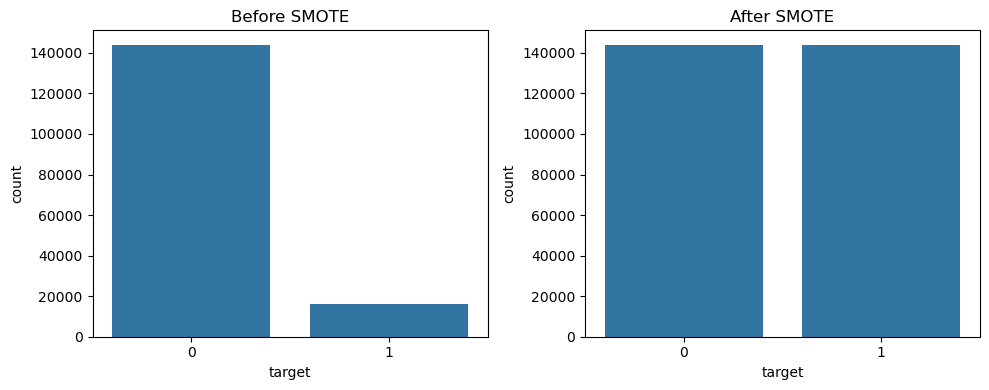

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before SMOTE")

sns.countplot(x=y_train_smote, ax=axes[1])
axes[1].set_title("After SMOTE")

plt.tight_layout()
plt.show()

### Observation

- Before applying SMOTE, the training dataset was highly imbalanced, with the majority class significantly outnumbering the minority class.
- After applying SMOTE, both classes contained an equal number of observations.
- SMOTE was applied **only to the training dataset**, while the testing dataset remained unchanged to prevent data leakage.
- The balanced training dataset is expected to help the models learn the characteristics of the minority class more effectively, potentially improving Recall and F1-score.

# Logistic Regression after SMOTE

After balancing the training dataset using SMOTE, Logistic Regression is retrained to evaluate whether the additional synthetic minority-class samples improve the model's ability to identify transaction customers. The performance will be compared with the baseline Logistic Regression model trained on the original imbalanced dataset.

In [78]:
lr_smote = LogisticRegression(random_state=42)

lr_smote.fit(X_train_scaled_smote, y_train_scaled_smote)

LogisticRegression(random_state=42)

In [79]:
y_pred_lr_smote = lr_smote.predict(X_test_scaled)

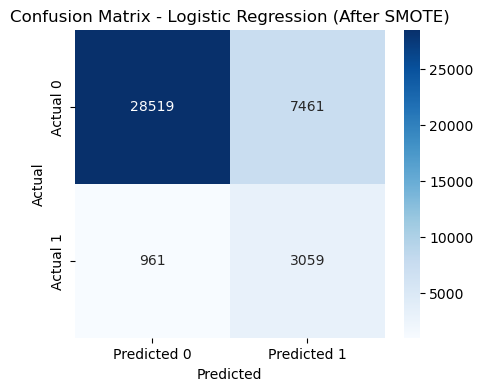

In [80]:
cm_lr_smote = confusion_matrix(y_test, y_pred_lr_smote)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm_lr_smote,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0","Predicted 1"],
    yticklabels=["Actual 0","Actual 1"]
)

plt.title("Confusion Matrix - Logistic Regression (After SMOTE)")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [81]:
accuracy_lr_smote = accuracy_score(y_test, y_pred_lr_smote)
precision_lr_smote = precision_score(y_test, y_pred_lr_smote)
recall_lr_smote = recall_score(y_test, y_pred_lr_smote)
f1_lr_smote = f1_score(y_test, y_pred_lr_smote)

y_prob_lr_smote = lr_smote.predict_proba(X_test_scaled)[:,1]

roc_auc_lr_smote = roc_auc_score(y_test, y_prob_lr_smote)

print(f"Accuracy : {accuracy_lr_smote:.4f}")
print(f"Precision: {precision_lr_smote:.4f}")
print(f"Recall   : {recall_lr_smote:.4f}")
print(f"F1 Score : {f1_lr_smote:.4f}")
print(f"ROC-AUC  : {roc_auc_lr_smote:.4f}")

print(classification_report(y_test, y_pred_lr_smote))

Accuracy : 0.7894
Precision: 0.2908
Recall   : 0.7609
F1 Score : 0.4208
ROC-AUC  : 0.8584
              precision    recall  f1-score   support

           0       0.97      0.79      0.87     35980
           1       0.29      0.76      0.42      4020

    accuracy                           0.79     40000
   macro avg       0.63      0.78      0.65     40000
weighted avg       0.90      0.79      0.83     40000



### Observation

- After applying SMOTE, the Logistic Regression model showed a significant improvement in detecting the minority class.
- The **Recall increased from 25.90% to 76.09%**, indicating that the model correctly identified a much larger proportion of customers who actually made a transaction.
- The **F1-score improved from 0.3754 to 0.4208**, demonstrating a better balance between Precision and Recall.
- Although **Accuracy decreased from 91.34% to 78.94%** and Precision also decreased, this was expected because the model became less biased toward the majority class and predicted more minority-class instances.
- The **ROC-AUC remained almost unchanged**, suggesting that the model's overall ability to distinguish between the two classes was maintained.
- Overall, SMOTE substantially improved the model's ability to detect transaction customers, making it more suitable for this imbalanced classification problem.

# XGBoost after SMOTE

After balancing the training dataset using SMOTE, XGBoost is retrained to evaluate whether synthetic minority-class samples improve its ability to detect customers who make a transaction. The performance of this model will be compared with the baseline XGBoost model trained on the original imbalanced dataset.

In [82]:
xgb_smote = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb_smote.fit(X_train_smote, y_train_smote)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [83]:
y_pred_xgb_smote = xgb_smote.predict(X_test)

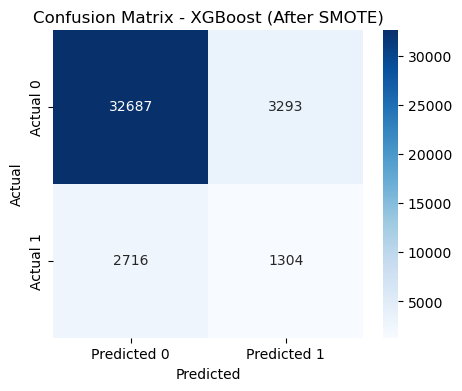

In [84]:
cm_xgb_smote = confusion_matrix(y_test, y_pred_xgb_smote)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm_xgb_smote,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.title("Confusion Matrix - XGBoost (After SMOTE)")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [85]:
accuracy_xgb_smote = accuracy_score(y_test, y_pred_xgb_smote)
precision_xgb_smote = precision_score(y_test, y_pred_xgb_smote)
recall_xgb_smote = recall_score(y_test, y_pred_xgb_smote)
f1_xgb_smote = f1_score(y_test, y_pred_xgb_smote)

y_prob_xgb_smote = xgb_smote.predict_proba(X_test)[:, 1]
roc_auc_xgb_smote = roc_auc_score(y_test, y_prob_xgb_smote)

print(f"Accuracy : {accuracy_xgb_smote:.4f}")
print(f"Precision: {precision_xgb_smote:.4f}")
print(f"Recall   : {recall_xgb_smote:.4f}")
print(f"F1 Score : {f1_xgb_smote:.4f}")
print(f"ROC-AUC  : {roc_auc_xgb_smote:.4f}")

print(classification_report(y_test, y_pred_xgb_smote))

Accuracy : 0.8498
Precision: 0.2837
Recall   : 0.3244
F1 Score : 0.3027
ROC-AUC  : 0.7353
              precision    recall  f1-score   support

           0       0.92      0.91      0.92     35980
           1       0.28      0.32      0.30      4020

    accuracy                           0.85     40000
   macro avg       0.60      0.62      0.61     40000
weighted avg       0.86      0.85      0.85     40000



### Observation

- After applying SMOTE, XGBoost identified more customers belonging to the minority class, increasing Recall from **24.08%** to **32.44%**.
- However, this improvement came at the cost of a substantial decrease in Precision, F1-score, and ROC-AUC.
- The Accuracy also decreased because the model predicted more observations as the minority class.
- Compared with Logistic Regression, XGBoost did not benefit significantly from SMOTE.
- Overall, SMOTE improved the minority-class detection of XGBoost but reduced its overall classification performance. 
- Therefore, the improvement was less effective than that observed for **Logistic Regression**.

# Hyperparameter Tuning using RandomizedSearchCV for Logistic Regression


After evaluating the baseline and SMOTE-based models, Logistic Regression trained on the SMOTE-balanced dataset was selected for further optimization.

 RandomizedSearchCV is used to systematically evaluate different combinations of hyperparameters using cross-validation. The objective is to identify the parameter combination that provides the best balance between Precision and Recall while improving the overall model performance.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

#### Parameters

In [87]:
param_dist = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],
    "penalty": ["l2"],
    "solver": ["lbfgs"]
}

#### RandomizedSearchCV

In [88]:

random_search = RandomizedSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=6,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=1
)


#### Hyperparameter Search

In [89]:
random_search.fit(X_train_scaled_smote, y_train_scaled_smote)

RandomizedSearchCV(cv=3, estimator=LogisticRegression(random_state=42),
                   n_iter=6, n_jobs=1,
                   param_distributions={'C': [0.001, 0.01, 0.1, 1, 10, 100],
                                        'penalty': ['l2'],
                                        'solver': ['lbfgs']},
                   random_state=42, scoring='f1')

#### Best Parameters 

In [90]:
print("Best Parameters:", random_search.best_params_)
print("Best Cross Validation F1 Score:", random_search.best_score_)

Best Parameters: {'solver': 'lbfgs', 'penalty': 'l2', 'C': 0.01}
Best Cross Validation F1 Score: 0.8005895536934592


In [91]:
best_lr = random_search.best_estimator_

#### Model Prediction

In [92]:
y_pred_best = best_lr.predict(X_test_scaled)

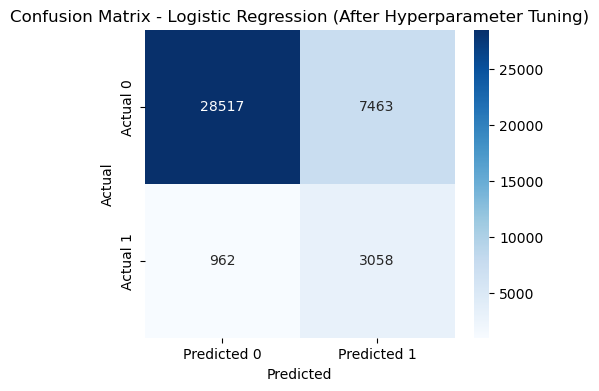

In [93]:
cm_best = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm_best,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.title("Confusion Matrix - Logistic Regression (After Hyperparameter Tuning)")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [94]:
accuracy_best = accuracy_score(y_test, y_pred_best)
precision_best = precision_score(y_test, y_pred_best)
recall_best = recall_score(y_test, y_pred_best)
f1_best = f1_score(y_test, y_pred_best)

y_prob_best = best_lr.predict_proba(X_test_scaled)[:, 1]
roc_auc_best = roc_auc_score(y_test, y_prob_best)

print(f"Accuracy : {accuracy_best:.4f}")
print(f"Precision: {precision_best:.4f}")
print(f"Recall   : {recall_best:.4f}")
print(f"F1 Score : {f1_best:.4f}")
print(f"ROC-AUC  : {roc_auc_best:.4f}")

print(classification_report(y_test, y_pred_best))

Accuracy : 0.7894
Precision: 0.2907
Recall   : 0.7607
F1 Score : 0.4206
ROC-AUC  : 0.8584
              precision    recall  f1-score   support

           0       0.97      0.79      0.87     35980
           1       0.29      0.76      0.42      4020

    accuracy                           0.79     40000
   macro avg       0.63      0.78      0.65     40000
weighted avg       0.90      0.79      0.83     40000



### Observation

- RandomizedSearchCV was applied to optimize the hyperparameters of the Logistic Regression model trained on the SMOTE-balanced dataset.
- The tuned model produced evaluation metrics that were nearly identical to those obtained before hyperparameter tuning.
- The confusion matrix also showed only negligible changes in the numbers of correctly and incorrectly classified observations.
- This indicates that the baseline Logistic Regression model was already close to its optimal configuration, and further hyperparameter tuning did not provide a meaningful improvement in predictive performance.
- Therefore, while RandomizedSearchCV confirmed the robustness of the model, it did not significantly improve Accuracy, Precision, Recall, F1-score, or ROC-AUC.

**Conclusion:**

 Hyperparameter tuning served as a validation step rather than a performance improvement step, confirming that the selected Logistic Regression model was already well-optimized.

## Threshold Optimization

In [96]:
y_prob = best_lr.predict_proba(X_test_scaled)[:, 1]

In [97]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    results.append([
        threshold,
        precision,
        recall,
        f1
    ])

In [98]:
threshold_df = pd.DataFrame(
    results,
    columns=[
        "Threshold",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

threshold_df

,Threshold,Precision,Recall,F1-Score
0,0.1,0.139639,0.972886,0.244224
1,0.2,0.174176,0.929851,0.293395
2,0.3,0.209319,0.882836,0.338403
3,0.4,0.248175,0.828607,0.381952
4,0.5,0.290657,0.760697,0.420604
5,0.6,0.339995,0.681343,0.453627
6,0.7,0.406213,0.595274,0.482898


In [99]:
threshold_df.sort_values(
    by="F1-Score",
    ascending=False
)

,Threshold,Precision,Recall,F1-Score
6,0.7,0.406213,0.595274,0.482898
5,0.6,0.339995,0.681343,0.453627
4,0.5,0.290657,0.760697,0.420604
3,0.4,0.248175,0.828607,0.381952
2,0.3,0.209319,0.882836,0.338403
1,0.2,0.174176,0.929851,0.293395
0,0.1,0.139639,0.972886,0.244224


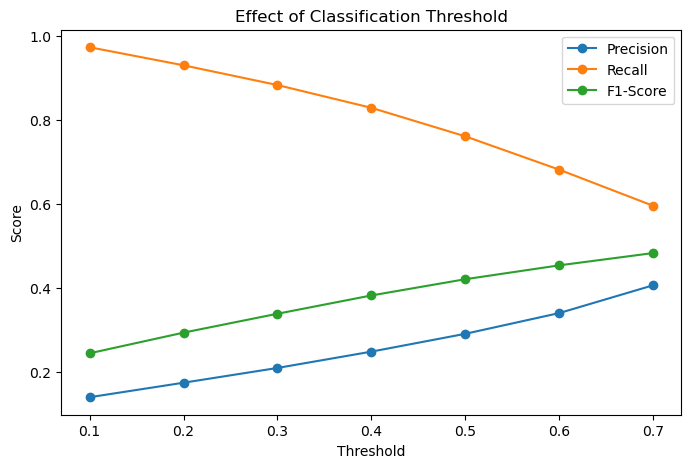

In [100]:
plt.figure(figsize=(8,5))

plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker='o', label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker='o', label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1-Score"], marker='o', label="F1-Score")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Effect of Classification Threshold")
plt.legend()

plt.show()

In [101]:
optimal_threshold = 0.7

y_pred_optimal = (y_prob >= optimal_threshold).astype(int)

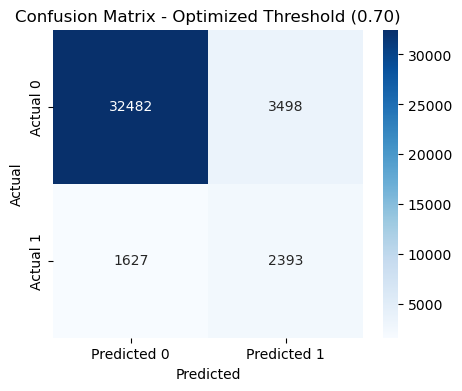

In [102]:
cm_optimal = confusion_matrix(y_test, y_pred_optimal)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm_optimal,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.title("Confusion Matrix - Optimized Threshold (0.70)")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [103]:
print(classification_report(y_test, y_pred_optimal))

print("Accuracy :", accuracy_score(y_test, y_pred_optimal))
print("Precision:", precision_score(y_test, y_pred_optimal))
print("Recall   :", recall_score(y_test, y_pred_optimal))
print("F1 Score :", f1_score(y_test, y_pred_optimal))

              precision    recall  f1-score   support

           0       0.95      0.90      0.93     35980
           1       0.41      0.60      0.48      4020

    accuracy                           0.87     40000
   macro avg       0.68      0.75      0.70     40000
weighted avg       0.90      0.87      0.88     40000

Accuracy : 0.871875
Precision: 0.4062128670853845
Recall   : 0.5952736318407961
F1 Score : 0.48289779033397234


### Observation

- Different classification thresholds were evaluated to identify the threshold that provides the best balance between Precision and Recall.
- As the classification threshold increased, **Precision increased**, while **Recall gradually decreased**, demonstrating the expected trade-off between these two metrics.
- The **F1-score** steadily improved across the evaluated thresholds and reached its highest value (**0.4829**) at a threshold of **0.70**.
- Compared with the default threshold (0.50), the optimized threshold significantly improved Precision (from **0.2908** to **0.4062**) while maintaining a reasonable Recall (**0.5953**), resulting in a better balance between false positives and false negatives.
- The confusion matrix confirms that the optimized threshold reduced the number of false positives while still correctly identifying a substantial number of positive cases.
- Based on these observations, a **classification threshold of 0.70** was selected as the optimal threshold for the final Logistic Regression model.

# 9.Why Logistic Regression?

Although XGBoost achieved competitive baseline performance, Logistic Regression responded more effectively to the model improvement techniques applied in this project.

After handling class imbalance using SMOTE and optimizing the classification threshold, Logistic Regression achieved the **highest F1-score (0.4829)** while maintaining a **strong ROC-AUC (0.8584)**. These improvements provided a better balance between Precision and Recall, making the model more suitable for identifying the minority class.

Therefore, Logistic Regression was selected as the final model for this customer transaction prediction task.

# 10.Final Model Comparison


In [106]:
master_comparison = pd.DataFrame({
    "Stage": [
        "Baseline Logistic Regression",
        "Logistic Regression + SMOTE",
        "Logistic Regression + SMOTE + RandomizedSearchCV",
        "Logistic Regression + SMOTE + Threshold Optimization (Final)"
    ],

    "Accuracy": [
        0.9134,
        accuracy_lr_smote,
        accuracy_best,
        accuracy_score(y_test, y_pred_optimal)
    ],

    "Precision": [
        0.6822,
        precision_lr_smote,
        precision_best,
        precision_score(y_test, y_pred_optimal)
    ],

    "Recall": [
        0.2590,
        recall_lr_smote,
        recall_best,
        recall_score(y_test, y_pred_optimal)
    ],

    "F1-Score": [
        0.3754,
        f1_lr_smote,
        f1_best,
        f1_score(y_test, y_pred_optimal)
    ],

    "ROC-AUC": [
        0.8599,
        roc_auc_lr_smote,
        roc_auc_best,
        roc_auc_best
    ]
}).round(4)

master_comparison

,Stage,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline Logistic Regression,0.9134,0.6822,0.2590,0.3754,0.8599
1,Logistic Regression + SMOTE,0.7894,0.2908,0.7609,0.4208,0.8584
2,Logistic Regression + SMOTE + RandomizedSearchCV,0.7894,0.2907,0.7607,0.4206,0.8584
3,Logistic Regression + SMOTE + Threshold Optimi...,0.8719,0.4062,0.5953,0.4829,0.8584


In [109]:
master_comparison["Remarks"] = [
    "Baseline Model",
    "Class Imbalance Handled",
    "Hyperparameters Optimized",
    "Final Selected Model"
]

master_comparison

,Stage,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Remarks
0,Baseline Logistic Regression,0.9134,0.6822,0.2590,0.3754,0.8599,Baseline Model
1,Logistic Regression + SMOTE,0.7894,0.2908,0.7609,0.4208,0.8584,Class Imbalance Handled
2,Logistic Regression + SMOTE + RandomizedSearchCV,0.7894,0.2907,0.7607,0.4206,0.8584,Hyperparameters Optimized
3,Logistic Regression + SMOTE + Threshold Optimi...,0.8719,0.4062,0.5953,0.4829,0.8584,Final Selected Model


In [108]:
master_comparison = master_comparison[
    [
        "Stage",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "Remarks"
    ]
]

## Final Observation

The Logistic Regression model was progressively improved through multiple optimization stages to address the challenges of class imbalance and improve minority class prediction.

- The **Baseline Logistic Regression** model achieved the highest Accuracy (91.34%) but showed low Recall (25.90%), indicating that many positive transactions were missed.
- Applying **SMOTE** significantly improved Recall (76.09%) and increased the F1-score, enabling the model to better identify the minority class.
- **RandomizedSearchCV** produced only negligible changes in the evaluation metrics, confirming that the SMOTE-based Logistic Regression model was already close to its optimal hyperparameter configuration.
- **Threshold Optimization** further improved the balance between Precision and Recall by increasing the classification threshold to **0.70**. This resulted in the **highest F1-score (0.4829)** while maintaining a strong ROC-AUC.
- Based on the overall evaluation, **Logistic Regression with SMOTE and threshold optimization** was selected as the final model because it provided the best balance between identifying positive transactions and minimizing false predictions.

# 11.ROC Curve

The Receiver Operating Characteristic (ROC) Curve illustrates the trade-off between the True Positive Rate (Recall) and the False Positive Rate across different classification thresholds.

The Area Under the ROC Curve (ROC-AUC) summarizes the model's ability to distinguish between the positive and negative classes. A higher ROC-AUC indicates better classification performance.

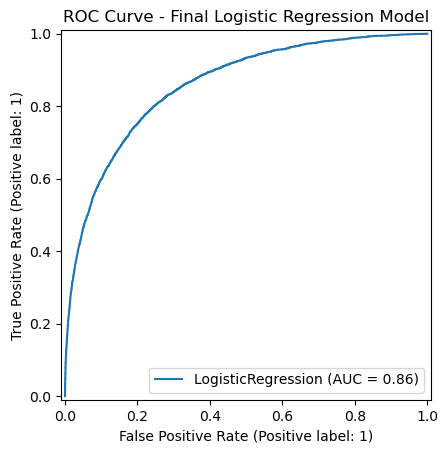

In [110]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(
    best_lr,
    X_test_scaled,
    y_test
)

plt.title("ROC Curve - Final Logistic Regression Model")
plt.show()

### Observation

- The ROC curve lies well above the diagonal reference line, indicating that the final Logistic Regression model performs substantially better than random guessing.
- The model achieved a **ROC-AUC of 0.8584**, demonstrating good discriminative ability between customers who perform transactions and those who do not.
- A high ROC-AUC indicates that the model maintains a strong balance between the True Positive Rate and False Positive Rate across different classification thresholds.
- The ROC curve confirms that the final model retains strong ranking capability even after applying SMOTE and threshold optimization.

# 12.Precision-Recall Curve

For imbalanced datasets, the Precision-Recall Curve provides a more informative evaluation than the ROC Curve. It illustrates the trade-off between Precision and Recall across different decision thresholds and helps assess the model's performance on the minority class.

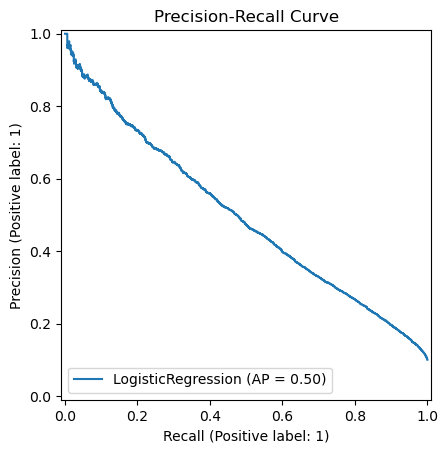

In [111]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_estimator(
    best_lr,
    X_test_scaled,
    y_test
)

plt.title("Precision-Recall Curve")
plt.show()

### Observation

- The ROC curve lies well above the diagonal reference line, indicating that the final Logistic Regression model performs substantially better than random guessing.
- The model achieved a **ROC-AUC of 0.8584**, demonstrating good discriminative ability between customers who perform transactions and those who do not.
- A high ROC-AUC indicates that the model maintains a strong balance between the True Positive Rate and False Positive Rate across different classification thresholds.
- The ROC curve confirms that the final model retains strong ranking capability even after applying SMOTE and threshold optimization.

# 13. Feature Importance (Logistic Regression Coefficients)

Although the feature names are anonymized, the coefficients of the Logistic Regression model provide an indication of the relative importance of each feature in the prediction process. Features with larger absolute coefficient values have a stronger influence on the model's predictions.

In [ ]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": best_lr.coef_[0]
})

coef_df["Absolute Coefficient"] = coef_df["Coefficient"].abs()

coef_df = coef_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

coef_df.head(20)

In [ ]:
top20 = coef_df.head(20)

plt.figure(figsize=(10,6))

plt.barh(
    top20["Feature"],
    top20["Absolute Coefficient"]
)

plt.title("Top 20 Important Features")
plt.xlabel("Absolute Coefficient")

plt.gca().invert_yaxis()

plt.show()

### Observation

- The feature importance plot ranks the top 20 variables based on the absolute values of the Logistic Regression coefficients.
- Features such as **var_81**, **var_139**, **var_6**, **var_53**, and **var_146** contribute the most to the model's predictions.
- Because the dataset contains anonymized feature names, the individual variables cannot be interpreted from a business perspective. However, their coefficient magnitudes indicate their relative influence on the classification decision.
- The distribution of feature importance suggests that the model relies on multiple informative features rather than a single dominant variable, indicating that prediction is driven by a combination of feature contributions.

## Overall Model Evaluation

The final Logistic Regression model was comprehensively evaluated using multiple performance metrics and visualization techniques.

- The ROC Curve demonstrated strong discriminative performance with a **ROC-AUC of 0.8584**.
- The Precision-Recall Curve confirmed the model's ability to effectively identify the minority class despite the class imbalance.
- Feature importance analysis showed that the model's predictions are influenced by several informative features rather than a single dominant variable.
- Combined with SMOTE and threshold optimization, these results indicate that the final Logistic Regression model is robust, well-balanced, and suitable for the customer transaction prediction task.

# 14.Saving the Final Model

The final Logistic Regression model, trained using the SMOTE-balanced dataset and optimized with the selected classification threshold, was saved for future use. Saving the trained model enables it to be reused for prediction without repeating the entire training process, making deployment and integration into production systems more efficient.

In [115]:
import joblib

joblib.dump(best_lr, "customer_transaction_model.pkl")

print("Model saved successfully.")

Model saved successfully.


In [116]:
joblib.dump(scaler, "standard_scaler.pkl")

print("Scaler saved successfully.")

Scaler saved successfully.


# 15.Final Conclusion

This project developed a machine learning solution to predict customer transactions using the Santander Customer Transaction Prediction dataset.

Five baseline machine learning models were evaluated, including Logistic Regression, Decision Tree, Random Forest, XGBoost, and Support Vector Machine. Logistic Regression demonstrated the most balanced performance for the minority class.

To further improve performance, the training dataset was balanced using SMOTE. This significantly increased the model's Recall and improved its F1-score. Hyperparameter tuning using RandomizedSearchCV confirmed that the SMOTE-based Logistic Regression model was already close to its optimal configuration.

Finally, threshold optimization was performed by evaluating multiple classification thresholds. Selecting a threshold of **0.70** improved the F1-score while maintaining a better balance between Precision and Recall.

The final Logistic Regression model, trained on the SMOTE-balanced dataset and optimized using threshold selection, was chosen as the best-performing model for this classification task.

# 16.Business Impact

The final model can help financial institutions identify customers who are more likely to perform transactions. This can support targeted marketing campaigns, personalized offers, and better resource allocation.

# 17.Business Recommendation

The final model can be used to identify customers who are more likely to perform transactions. Such predictions can support targeted marketing campaigns, personalized offers, and better allocation of business resources.

# 18.Limitations

- The feature names are anonymized, limiting business interpretation.
- The dataset is highly imbalanced.
- The model was evaluated using a single train-test split.

# 19.Future Scope

The following improvements can be explored in future work:

- Apply advanced boosting algorithms such as LightGBM and CatBoost.
- Perform feature selection to reduce dimensionality.
- Explore additional imbalance handling techniques such as ADASYN and SMOTEENN.
- Optimize the classification threshold using business-specific objectives.
- Deploy the trained model using Streamlit or FastAPI.
- Monitor model performance using real-world customer transaction data.